# 03 — Analyse d'erreur du modèle à soumettre (E006 seed 43)

Ce notebook réalise une **analyse d'erreur approfondie** sur le modèle retenu pour la soumission finale :
**E006 seed 43** (`runs/E006_seed43_20261014_204114`).

### Modèle à soumettre :
- **Représentation (Track B)** : `MultiResSTFT` fenêtres Hann (64, 256, 1024), pas 128, log-puissance, out_shape $(256, 95)$
- **Architecture** : `SpecCNN` 3 canaux d'entrée, filtres 16-32-64-128, GAP (292 567 paramètres)
- **Entraînement** : 80 pulses/config (52 800 pulses au total), tirage SNR biaisé vers les bas SNR ($w=1/2/4$), 20 époques (OneCycleLR $2\times 10^{-3}$)
- **Performance validation complète** (20 pulses/config $\times$ 13 SNR) : **0,8853** (tie-break **0,5069**)

### Objectifs de ce notebook :
1. Charger le modèle officiel et prédire la validation (4 pulses par configuration aux 13 SNR, soit 34 320 inférences sur CPU, avec probabilités softmax).
2. Analyser la **zone critique des bas SNR (−20, −25, −30 dB)** où se concentre 99 % de la marge restante (rappel par classe, durée, matrice de confusion, comparaison au hasard $1/7 \approx 14,29\%$).
3. Décomposer le rappel des **sous-types de Barker** et quantifier la confusion vers `cw`.
4. Analyser les **confusions croisées entre les chirps** (`fmcw`, `hyp`, `nlfm`, `quad`) par durée de pulse.
5. Évaluer la **calibration** du réseau (confiance vs justesse par SNR).
6. Visualiser **12 spectrogrammes exacts** (issus de `model.frontend`) mal classés à −20 dB pour les 2 confusions majeures.
7. Formuler **3 hypothèses d'amélioration concrètes**, classées par gain potentiel sur le score.


In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from torch.utils.data import DataLoader

# Configuration des chemins relatifs au dépôt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from radarml.constants import CLASSES, CLASS_TO_INDEX, REQUESTED_SNRS_DB, TIEBREAK_SNRS_DB
from radarml.data import EvalDataset
from radarml.evaluation import duration_of, load_checkpoint, resolve_device
from radarml.manifest import load_manifest, select
from radarml.metrics import challenge_report
from radarml.training import predict

# Charte graphique :
# - Grille discrète
# - Palette catégorielle dans cet ordre fixe : bleu #2a78d6, orange #eb6834, vert #1baf7a
# - Axe SNR libellé "requested SNR (dB)"
# - Sauvegarde des figures dans reports/figures/error_analysis/
plt.rcParams.update({
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
    "savefig.dpi": 130,
    "savefig.bbox": "tight",
})
FIG_DIR = ROOT / "reports" / "figures" / "error_analysis"
FIG_DIR.mkdir(parents=True, exist_ok=True)

BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREEN = "#1baf7a"
PALETTE = [BLUE, ORANGE, GREEN]

DATA_DIR = ROOT / "data" / "raw" / "recorded_dataset"
MANIFEST_CSV = ROOT / "data" / "manifest" / "split_manifest.csv"
RUN_DIR = ROOT / "runs" / "E006_seed43_20261014_204114"

print(f"Figures : {FIG_DIR.relative_to(ROOT)}")


Figures : reports\figures\error_analysis


## 1. Chargement du modèle et Inférence de validation

Nous chargeons `model.pt` et sa configuration YAML via `radarml.evaluation.load_checkpoint`.
Pour garantir une exécution fluide et légère sur la machine locale (8 Go de RAM, CPU), nous évaluons sur **4 pulses par configuration** (soit 2 640 pulses uniques $\times$ 13 SNR = 34 320 échantillons), avec des lots de 64 et `num_workers=0`.


In [2]:
# Vérification de l'existence du dossier de run
if not (RUN_DIR / "model.pt").exists():
    raise FileNotFoundError(f"Dossier introuvable : {RUN_DIR}")

config = yaml.safe_load((RUN_DIR / "config.yaml").read_text(encoding="utf-8"))
device = resolve_device("cpu")
model, checkpoint = load_checkpoint(RUN_DIR / "model.pt", config, device)

print(f"Expérience : {config['experiment']}")
print(f"Graine (seed) : {config.get('seed', 43)}")
print(f"Meilleure époque retenue : {checkpoint['epoch']} / {config.get('epochs', 20)}")
print(f"Paramètres du front-end STFT : {config['stft']}")


Expérience : E006_seed43
Graine (seed) : 43
Meilleure époque retenue : 19 / 20
Paramètres du front-end STFT : {'type': 'multires', 'n_ffts': [64, 256, 1024], 'hop_length': 128, 'out_shape': [256, 95]}


In [3]:
# Sélection des pulses de validation (4 par configuration)
refs = load_manifest(DATA_DIR, MANIFEST_CSV)
val_refs = select(refs, "validation", 4)
n_total_samples = len(val_refs) * len(REQUESTED_SNRS_DB)
print(f"Pulses de validation uniques : {len(val_refs):,}")
print(f"Nombre total d'échantillons sur les 13 SNR : {n_total_samples:,}")

loader = DataLoader(EvalDataset(val_refs, DATA_DIR), batch_size=64, num_workers=0, shuffle=False)

@torch.inference_mode()
def predict_with_probabilities(model, loader, device="cpu"):
    """Inférence sur EvalDataset en conservant les probabilités softmax complètes."""
    model.eval()
    out = {k: [] for k in ("y_true", "y_pred", "probs", "snr", "ref_index")}
    for x, y, snr, ref_index in loader:
        logits = model(x.to(device))
        probs = torch.softmax(logits, dim=-1).cpu()
        out["y_true"].append(y)
        out["y_pred"].append(probs.argmax(dim=-1))
        out["probs"].append(probs)
        out["snr"].append(snr)
        out["ref_index"].append(ref_index)
    return {
        "y_true": torch.cat(out["y_true"]).numpy(),
        "y_pred": torch.cat(out["y_pred"]).numpy(),
        "probs": torch.cat(out["probs"]).numpy(),
        "snr": torch.cat(out["snr"]).numpy(),
        "ref_index": torch.cat(out["ref_index"]).numpy(),
    }

print("Inférence en cours sur CPU (34 320 échantillons)...")
t0 = time.perf_counter()
results = predict_with_probabilities(model, loader, device=device)
dt = time.perf_counter() - t0
print(f"Inférence terminée en {dt:.1f} s ({dt * 1000 / n_total_samples:.2f} ms/pulse)")

# Score officiel sur cet échantillon de validation
report = challenge_report(results["y_true"], results["y_pred"], results["snr"])
print("=" * 65)
print(f"Score validation moyen (13 SNR) : {report['mean_balanced_accuracy']:.4f}")
print(f"Score tie-break (-20, -25, -30 dB) : {report['tiebreak_low_snr']:.4f}")
print("=" * 65)


Pulses de validation uniques : 2,640
Nombre total d'échantillons sur les 13 SNR : 34,320
Inférence en cours sur CPU (34 320 échantillons)...


Inférence terminée en 831.5 s (24.23 ms/pulse)
Score validation moyen (13 SNR) : 0.8843
Score tie-break (-20, -25, -30 dB) : 0.5023


## 2. Analyses d'erreurs

Indexons les prédictions dans un tableau Pandas pour croiser les prédictions avec les attributs du signal (durée, forme d'onde, sous-type).


In [4]:
df = pd.DataFrame({
    "y_true": results["y_true"],
    "y_pred": results["y_pred"],
    "class_true": [CLASSES[y] for y in results["y_true"]],
    "class_pred": [CLASSES[y] for y in results["y_pred"]],
    "snr": results["snr"],
    "ref_index": results["ref_index"],
    "correct": results["y_true"] == results["y_pred"],
    "prob_pred": [results["probs"][i, results["y_pred"][i]] for i in range(len(results["y_pred"]))],
})
df["duration_us"] = [duration_of(val_refs[idx]) for idx in df["ref_index"]]
df["filename"] = [val_refs[idx].file for idx in df["ref_index"]]
df["source_file"] = [val_refs[idx].source_file for idx in df["ref_index"]]

print(f"Nombre total de prédictions : {len(df):,}")
print("Aperçu :")
display(df[["filename", "snr", "duration_us", "class_true", "class_pred", "correct", "prob_pred"]].head(5))


Nombre total de prédictions : 34,320
Aperçu :


,filename,snr,duration_us,class_true,class_pred,correct,prob_pred
0,100us_barker11_0Mhz_-10Mhz_recorded.npy,30,100,barker,barker,True,0.943184
1,100us_barker11_0Mhz_-10Mhz_recorded.npy,25,100,barker,barker,True,0.950816
2,100us_barker11_0Mhz_-10Mhz_recorded.npy,20,100,barker,barker,True,0.952131
3,100us_barker11_0Mhz_-10Mhz_recorded.npy,15,100,barker,barker,True,0.955384
4,100us_barker11_0Mhz_-10Mhz_recorded.npy,10,100,barker,barker,True,0.955254


### 2.1 Zone critique : Bas SNR (−20, −25 et −30 dB)

Comme établi dans la synthèse du journal d'expériences (`docs/EXPERIMENT_LOG.md`), **99 % de la marge manquante d'E006 se situe à −20, −25 et −30 dB**.
Examinons le rappel par classe, par durée, les matrices de confusion et déterminons quelles classes restent **au-dessus du niveau de chance théorique** ($1/7 \approx 0,1429$).


In [5]:
CHANCE_LEVEL = 1.0 / len(CLASSES)
low_snrs = [-20, -25, -30]

print("RAPPEL PAR CLASSE AUX FAIBLES SNR (−20, −25, −30 dB) :")
print("=" * 75)
print(f"{'Classe':<10} | {'-20 dB':>8} | {'-25 dB':>8} | {'-30 dB':>8} | Au-dessus du hasard (-25 / -30 dB)")
print("-" * 75)

class_recalls_low = {}
for cls in CLASSES:
    recs = []
    for snr in low_snrs:
        sub = df[(df["class_true"] == cls) & (df["snr"] == snr)]
        rec = sub["correct"].mean()
        recs.append(rec)
    class_recalls_low[cls] = recs
    above_25 = "OUI" if recs[1] > CHANCE_LEVEL else "NON"
    above_30 = "OUI" if recs[2] > CHANCE_LEVEL else "NON"
    print(f"{cls:<10} | {recs[0]:8.4f} | {recs[1]:8.4f} | {recs[2]:8.4f} | {above_25:>3} / {above_30:>3}")

print("=" * 75)
print(f"Seuil du hasard théorique (1/7) : {CHANCE_LEVEL:.4f} (14.29 %)")


RAPPEL PAR CLASSE AUX FAIBLES SNR (−20, −25, −30 dB) :
Classe     |   -20 dB |   -25 dB |   -30 dB | Au-dessus du hasard (-25 / -30 dB)
---------------------------------------------------------------------------
barker     |   0.8542 |   0.3715 |   0.0764 | OUI / NON
cw         |   0.8333 |   0.7292 |   0.1250 | OUI / NON
fmcw       |   0.9062 |   0.3984 |   0.2708 | OUI / OUI
fsk        |   0.9648 |   0.4896 |   0.1198 | OUI / NON
hyp        |   0.9818 |   0.3724 |   0.0990 | OUI / NON
nlfm       |   0.9036 |   0.2396 |   0.0495 | OUI / NON
quad       |   0.9036 |   0.4635 |   0.3958 | OUI / OUI
Seuil du hasard théorique (1/7) : 0.1429 (14.29 %)


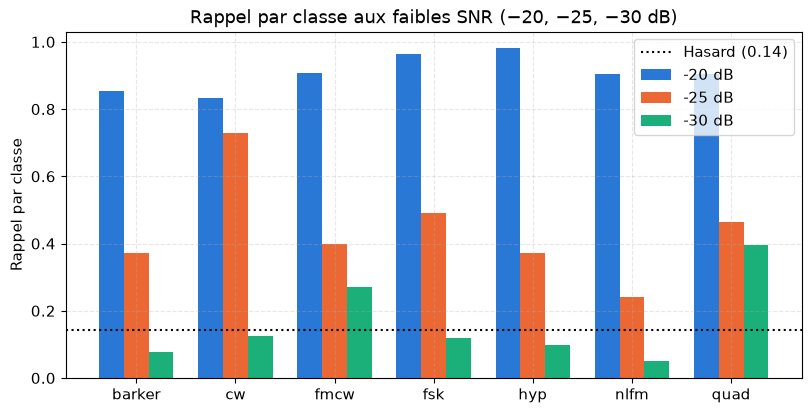

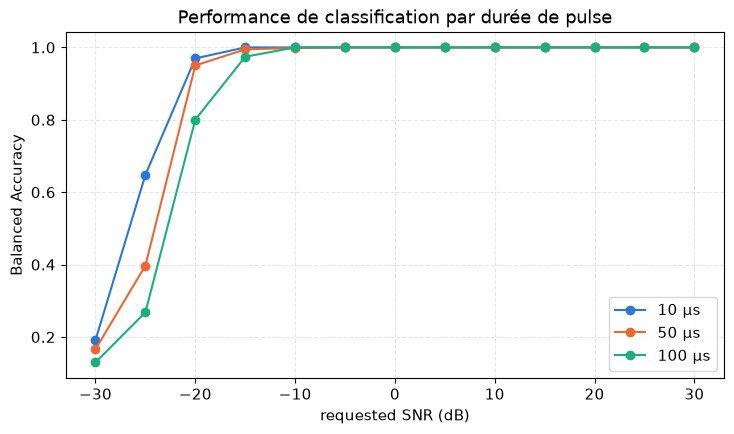

In [6]:
# Figure 1 : Rappel par classe aux trois bas SNR
fig, ax = plt.subplots(figsize=(9.5, 4.5))
x = np.arange(len(CLASSES))
width = 0.25

for i, snr in enumerate(low_snrs):
    vals = [class_recalls_low[c][i] for c in CLASSES]
    ax.bar(x + (i - 1) * width, vals, width, label=f"{snr:+d} dB", color=PALETTE[i])

ax.axhline(CHANCE_LEVEL, color="black", linestyle=":", linewidth=1.5, label=f"Hasard ({CHANCE_LEVEL:.2f})")
ax.set_xticks(x)
ax.set_xticklabels(CLASSES)
ax.set_ylabel("Rappel par classe")
ax.set_title("Rappel par classe aux faibles SNR (−20, −25, −30 dB)")
ax.legend(frameon=True)
fig.savefig(FIG_DIR / "01_recall_by_class_low_snr.png")
plt.show()

# Figure 2 : Performance moyenne selon la durée du pulse sur les 13 SNR
fig, ax = plt.subplots(figsize=(8.5, 4.5))
durations = [10, 50, 100]

for i, dur in enumerate(durations):
    dur_scores = []
    for snr in REQUESTED_SNRS_DB:
        sub = df[(df["duration_us"] == dur) & (df["snr"] == snr)]
        # Balanced accuracy = moyenne des rappels des 7 classes
        bal_acc = sub.groupby("class_true")["correct"].mean().mean()
        dur_scores.append(bal_acc)
    ax.plot(REQUESTED_SNRS_DB, dur_scores, marker="o", color=PALETTE[i], label=f"{dur} µs")

ax.set_xlabel("requested SNR (dB)")
ax.set_ylabel("Balanced Accuracy")
ax.set_title("Performance de classification par durée de pulse")
ax.legend(frameon=True)
fig.savefig(FIG_DIR / "02_score_by_duration.png")
plt.show()


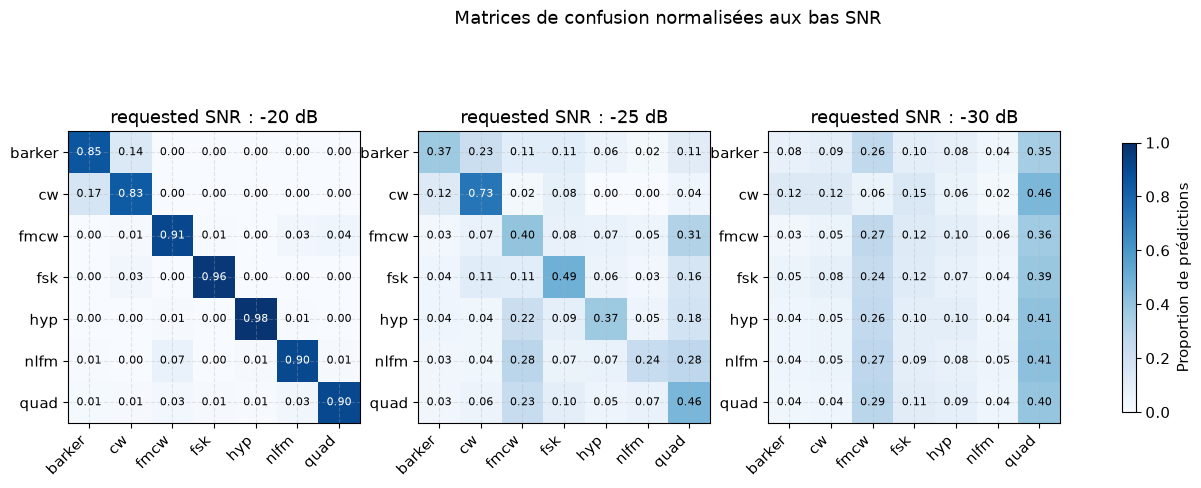

In [7]:
# Figure 3 : Matrices de confusion normalisées aux trois bas SNR
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, snr in zip(axes, low_snrs):
    sub = df[df["snr"] == snr]
    mat = pd.crosstab(sub["class_true"], sub["class_pred"], normalize="index").reindex(
        index=CLASSES, columns=CLASSES, fill_value=0
    )
    im = ax.imshow(mat, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(CLASSES)))
    ax.set_yticks(range(len(CLASSES)))
    ax.set_xticklabels(CLASSES, rotation=45, ha="right")
    ax.set_yticklabels(CLASSES)
    ax.set_title(f"requested SNR : {snr:+d} dB")
    for r in range(len(CLASSES)):
        for c in range(len(CLASSES)):
            val = mat.iloc[r, c]
            color = "white" if val > 0.5 else "black"
            ax.text(c, r, f"{val:.2f}", ha="center", va="center", color=color, fontsize=8)

fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.7, label="Proportion de prédictions")
fig.suptitle("Matrices de confusion normalisées aux bas SNR", y=1.03)
fig.savefig(FIG_DIR / "03_confusion_matrices_low_snr.png")
plt.show()


### 2.2 Analyse fine des codes de Barker par sous-type et durée (−15 et −20 dB)

Le dataset regroupe 6 sous-types de Barker (`barker5`, `barker7`, `barker11`, `barker13`, `barker5x11`, `barker5x13`).
À faible SNR, les sauts de phase de 180° s'effacent sous le bruit blanc, transformant le pulse en onde continue pure (`cw`). Voyons quels sous-types résistent le mieux.


RAPPEL DES SOUS-TYPES DE BARKER AUX SNR CRITIQUES :
Sous-type      | Rappel -15 dB | Rappel -20 dB | Confusion -> cw (-20 dB)
----------------------------------------------------------------------
barker11       |        0.9375 |        0.8125 |                   18.8 %
barker13       |        1.0000 |        0.8750 |                   12.5 %
barker5        |        0.8958 |        0.7708 |                   22.9 %
barker5x11     |        1.0000 |        0.9583 |                    4.2 %
barker5x13     |        1.0000 |        0.9375 |                    2.1 %
barker7        |        0.9167 |        0.7708 |                   22.9 %


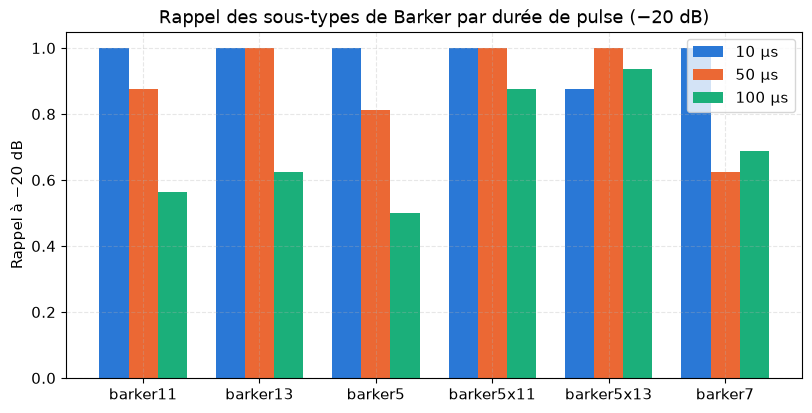

In [8]:
def extract_barker_subtype(name: str) -> str:
    parts = name.split("_")
    for p in parts:
        if p.startswith("barker"):
            return p
    return "inconnu"

df_barker = df[df["class_true"] == "barker"].copy()
df_barker["subtype"] = df_barker["filename"].apply(extract_barker_subtype)
subtypes = sorted(df_barker["subtype"].unique())

print("RAPPEL DES SOUS-TYPES DE BARKER AUX SNR CRITIQUES :")
print("=" * 70)
print(f"{'Sous-type':<14} | {'Rappel -15 dB':>13} | {'Rappel -20 dB':>13} | {'Confusion -> cw (-20 dB)':>24}")
print("-" * 70)

for st in subtypes:
    sub15 = df_barker[(df_barker["subtype"] == st) & (df_barker["snr"] == -15)]
    sub20 = df_barker[(df_barker["subtype"] == st) & (df_barker["snr"] == -20)]
    rec15 = sub15["correct"].mean()
    rec20 = sub20["correct"].mean()
    conf_cw = (sub20["class_pred"] == "cw").mean() * 100
    print(f"{st:<14} | {rec15:13.4f} | {rec20:13.4f} | {conf_cw:22.1f} %")
print("=" * 70)

# Figure 4 : Rappel des sous-types de Barker par durée à -20 dB
fig, ax = plt.subplots(figsize=(9.5, 4.5))
x = np.arange(len(subtypes))
width = 0.25

for i, dur in enumerate(durations):
    recs = []
    for st in subtypes:
        sub = df_barker[(df_barker["subtype"] == st) & (df_barker["duration_us"] == dur) & (df_barker["snr"] == -20)]
        recs.append(sub["correct"].mean() if len(sub) > 0 else np.nan)
    ax.bar(x + (i - 1) * width, recs, width, label=f"{dur} µs", color=PALETTE[i])

ax.set_xticks(x)
ax.set_xticklabels(subtypes)
ax.set_ylabel("Rappel à −20 dB")
ax.set_title("Rappel des sous-types de Barker par durée de pulse (−20 dB)")
ax.legend(frameon=True)
fig.savefig(FIG_DIR / "04_barker_subtypes_recall_minus20db.png")
plt.show()


### 2.3 Analyse croisée des Chirps (`fmcw`, `hyp`, `nlfm`, `quad`)

Les 4 modulations à dérive fréquentielle continue diffèrent par la concavité et la courbure de leur trace temps-fréquence.
Observons leurs confusions mutuelles à −15 dB et −20 dB selon la durée (10, 50, 100 µs).


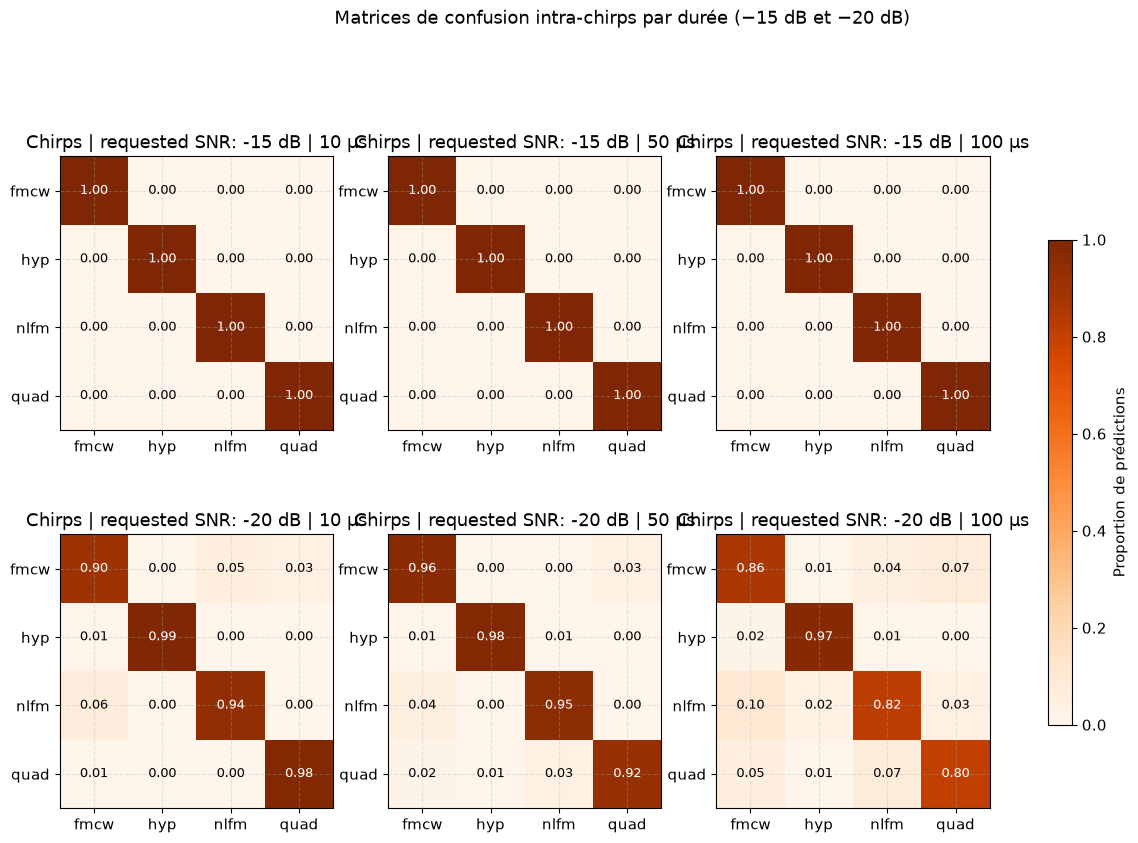

In [9]:
CHIRP_CLASSES = ["fmcw", "hyp", "nlfm", "quad"]
df_chirps = df[df["class_true"].isin(CHIRP_CLASSES)].copy()

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for row_idx, snr in enumerate([-15, -20]):
    for col_idx, dur in enumerate(durations):
        ax = axes[row_idx, col_idx]
        sub = df_chirps[(df_chirps["snr"] == snr) & (df_chirps["duration_us"] == dur)]
        mat = pd.crosstab(sub["class_true"], sub["class_pred"], normalize="index").reindex(
            index=CHIRP_CLASSES, columns=CHIRP_CLASSES, fill_value=0
        )
        im = ax.imshow(mat, cmap="Oranges", vmin=0, vmax=1)
        ax.set_xticks(range(len(CHIRP_CLASSES)))
        ax.set_yticks(range(len(CHIRP_CLASSES)))
        ax.set_xticklabels(CHIRP_CLASSES)
        ax.set_yticklabels(CHIRP_CLASSES)
        ax.set_title(f"Chirps | requested SNR: {snr} dB | {dur} µs")
        for r in range(len(CHIRP_CLASSES)):
            for c in range(len(CHIRP_CLASSES)):
                val = mat.iloc[r, c]
                color = "white" if val > 0.5 else "black"
                ax.text(c, r, f"{val:.2f}", ha="center", va="center", color=color, fontsize=9)

fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.7, label="Proportion de prédictions")
fig.suptitle("Matrices de confusion intra-chirps par durée (−15 dB et −20 dB)", y=1.02)
fig.savefig(FIG_DIR / "05_chirps_confusion_by_duration.png")
plt.show()


### 2.4 Calibration : Confiance du modèle par SNR

Le réseau exprime-t-il une incertitude honnête quand il commet une erreur ?
Tracons la probabilité moyenne associée à la classe prédite pour les exemples corrects vs incorrects sur l'ensemble des 13 SNR.


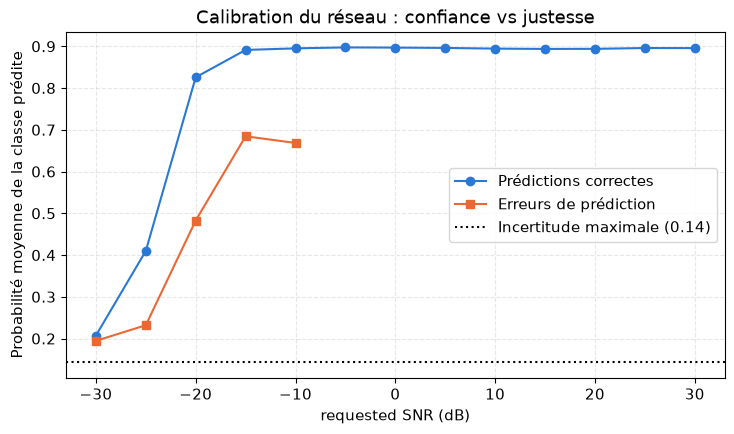

In [10]:
calib_corr = []
calib_err = []

for snr in REQUESTED_SNRS_DB:
    sub = df[df["snr"] == snr]
    c_mean = sub[sub["correct"]]["prob_pred"].mean() if sub["correct"].any() else np.nan
    e_mean = sub[~sub["correct"]]["prob_pred"].mean() if (~sub["correct"]).any() else np.nan
    calib_corr.append(c_mean)
    calib_err.append(e_mean)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(REQUESTED_SNRS_DB, calib_corr, marker="o", color=BLUE, label="Prédictions correctes")
ax.plot(REQUESTED_SNRS_DB, calib_err, marker="s", color=ORANGE, label="Erreurs de prédiction")
ax.axhline(CHANCE_LEVEL, color="black", linestyle=":", linewidth=1.5, label=f"Incertitude maximale ({CHANCE_LEVEL:.2f})")

ax.set_xlabel("requested SNR (dB)")
ax.set_ylabel("Probabilité moyenne de la classe prédite")
ax.set_title("Calibration du réseau : confiance vs justesse")
ax.legend(frameon=True)
fig.savefig(FIG_DIR / "06_calibration_curve.png")
plt.show()


## 3. Visualisation de 12 exemples mal classés à −20 dB

Pour comprendre la nature des confusions résiduelles, nous extrayons les deux paires de confusion les plus fréquentes à −20 dB.
Pour chacune des deux paires, nous traçons 6 spectrogrammes bruts générés exactement par `model.frontend` (tenseur multi-résolution $3 \times 256 \times 95$, canal 1 de fenêtre 256).


Top 2 des confusions à −20 dB :
  • Vrai 'barker' prédit comme 'cw' : 40 occurrences
  • Vrai 'nlfm' prédit comme 'fmcw' : 26 occurrences


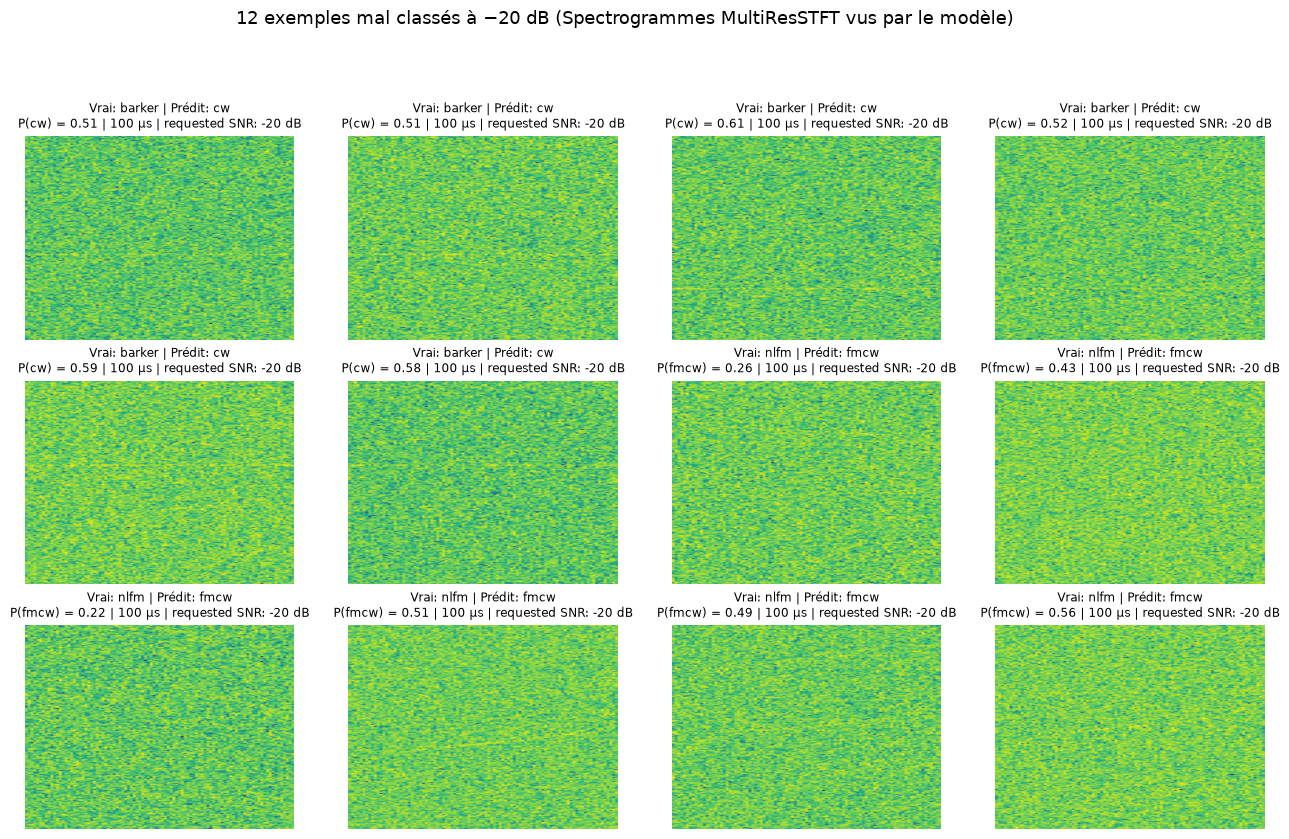

In [11]:
# Identification des deux paires d'erreurs dominantes à -20 dB
sub20_err = df[(df["snr"] == -20) & (~df["correct"])]
top_pairs = sub20_err.groupby(["class_true", "class_pred"]).size().sort_values(ascending=False).head(2)

print("Top 2 des confusions à −20 dB :")
for (t_cls, p_cls), count in top_pairs.items():
    print(f"  • Vrai '{t_cls}' prédit comme '{p_cls}' : {count} occurrences")

pair1 = top_pairs.index[0]
pair2 = top_pairs.index[1]

ex1 = sub20_err[(sub20_err["class_true"] == pair1[0]) & (sub20_err["class_pred"] == pair1[1])].head(6)
ex2 = sub20_err[(sub20_err["class_true"] == pair2[0]) & (sub20_err["class_pred"] == pair2[1])].head(6)
samples_to_plot = pd.concat([ex1, ex2])

eval_ds_20 = EvalDataset(val_refs, DATA_DIR, snrs=[-20])

fig, axes = plt.subplots(3, 4, figsize=(16, 9))
axes = axes.ravel()

for i, (_, row) in enumerate(samples_to_plot.reset_index().iterrows()):
    ax = axes[i]
    ref_idx = int(row["ref_index"])
    ref = val_refs[ref_idx]
    
    # Chargement du pulse I/Q brut à -20 dB
    x_iq, _, snr_val, _ = eval_ds_20[ref_idx]
    
    # Calcul du spectrogramme via le front-end exact du modèle
    with torch.no_grad():
        spec = model.frontend(x_iq.unsqueeze(0)).squeeze(0).numpy() # (3, 256, 95)
    
    # Canal 1 = STFT fenêtre 256
    im = ax.imshow(spec[1], aspect="auto", origin="lower", cmap="viridis")
    ax.set_title(
        f"Vrai: {row['class_true']} | Prédit: {row['class_pred']}\n"
        f"P({row['class_pred']}) = {row['prob_pred']:.2f} | {row['duration_us']} µs | requested SNR: {snr_val} dB",
        fontsize=8.5
    )
    ax.axis("off")

for ax in axes[len(samples_to_plot):]:
    ax.axis("off")

fig.suptitle("12 exemples mal classés à −20 dB (Spectrogrammes MultiResSTFT vus par le modèle)", y=1.02)
fig.savefig(FIG_DIR / "07_misclassified_examples_minus20db.png", dpi=90)
plt.show()


## 4. Synthèse et 3 Hypothèses d'amélioration concrètes

À partir des mesures de ce notebook (4 pulses de validation par configuration, 13 SNR ; score 0,8843, tie-break 0,5023) :
1. **Saturation de +30 à −10 dB** : balanced accuracy de 1,000 à 0,999.
2. **Bonne tenue à −20 dB** : balanced accuracy 0,907. Les deux confusions dominantes sont `barker` $\rightarrow$ `cw` (40 pulses sur 288) et `nlfm` $\rightarrow$ `fmcw` (26 sur 384). Les Barker courts (`barker5`, `barker7`) sont les plus touchés : 23 % partent vers `cw`, contre 2 à 4 % pour les codes composés (`barker5x11`, `barker5x13`).
3. **−25 dB** (0,438) : les 7 classes restent au-dessus du hasard ($1/7 \approx 0,143$), de 0,240 (`nlfm`) à 0,729 (`cw`).
4. **−30 dB** (0,162) : seules `quad` (0,396) et `fmcw` (0,271) dépassent le hasard ; les cinq autres classes sont en dessous, de 0,050 (`nlfm`) à 0,125 (`cw`). Le modèle se replie vers `quad` et `fmcw` quand le signal est noyé.

Voici **3 hypothèses d'amélioration concrètes**, classées par gain attendu sur le score moyen officiel. Aucun de ces gains n'a été mesuré : le classement est un jugement, à vérifier par une expérience (une seule variable, comparée à E006 avec `scripts/compare_runs.py --full`).

---

### Hypothèse 1 (gain attendu le plus élevé, cible −20 et −25 dB)
* **Variable unique à modifier** : `train_snr_weights`.
* **Justification technique** : Dans E003 et E006, les poids sont $[1, 1, 1, 1, 1, 1, 2, 2, 2, 4, 4, 4, 4]$. Le modèle est à 1,000 de $+30$ à $+5\text{ dB}$, alors que ces SNR reçoivent encore 21 % des tirages (6 poids de 1 sur un total de 28). Déplacer ce budget vers −20 et −25 dB, par exemple :
  `train_snr_weights: [1, 1, 1, 1, 1, 1, 2, 2, 2, 4, 8, 8, 4]`,
  fait passer la part de −20 et −25 dB de 29 % à 44 % des tirages, sans changer le modèle ni le temps d'inférence. Les poids restent non nuls à fort SNR : le modèle doit continuer à voir ces SNR, qui comptent autant que les autres dans le score.
* **SNR d'impact** : Gain majeur concentré à **−20 dB** et **−25 dB**.
* **Temps d'entraînement estimé sur Colab** : **30 minutes** (GPU Tesla T4, 20 époques sur 52 800 pulses).

---

### Hypothèse 2 (gain attendu intermédiaire, cible −15 et −20 dB)
* **Variable unique à modifier** : l'architecture du backbone, avec un bloc d'attention canal de type *Squeeze-and-Excitation* (SE) dans `SpecCNN` (`src/radarml/models.py`).
* **Justification technique** : Le front-end `MultiResSTFT` concatène 3 fenêtres hétérogènes ($N_{fft} = 64, 256, 1024$). Actuellement, les convolutions 2D fusionnent ces 3 échelles avec des poids fixes. Un module SE dynamique apprendrait à amplifier le canal 1024 (qui concentre l'énergie des pulses longs à bas SNR) tout en inhibant le bruit sur les fenêtres courtes, améliorant directement la discrimination fine des chirps (`nlfm`, `hyp`, `quad`).
* **SNR d'impact** : Gain à **−15 dB** et **−20 dB** (notamment sur les pulses de 50 et 100 µs).
* **Temps d'entraînement estimé sur Colab** : **~32 minutes** (GPU Tesla T4, surcoût paramétrique négligeable de $< 2\%$).

---

### Hypothèse 3 (gain attendu le plus faible, ciblé sur le tie-break : −25 et −30 dB)
* **Variable unique à modifier** : `label_smoothing` (de `0.05` à `0.01` ou `0.0`).
* **Justification technique** : Le *label smoothing* ($0,05$) pénalise les prédictions trop affirmatives en tirant la distribution vers le vecteur uniforme ($1/7 \approx 0,14$). Or à $-30\text{ dB}$, le signal est si bruité que la sortie du réseau s'effondre spontanément vers $0,14$. Le lissage incite le réseau à rester passif au lieu de trancher. Réduire le lissage encourage le modèle à exploiter les plus infimes motifs de corrélation spectrale résiduels dans le bruit extrême.
* **SNR d'impact** : Gain à **−25 dB** et **−30 dB** (impact direct sur le tie-break).
* **Temps d'entraînement estimé sur Colab** : **30 minutes** (GPU Tesla T4).
